# 02 · Manifold — Zhang 2019 Follicular Lymphoma

Fit the cell-state trajectory. First establish **which region carries the embryonic axis**: on the whole
malignant manifold the pSom module is confounded by proliferation (pSom↔cycling r≈+0.6, concentrated in
the 95%-cycling lobe from 01). Scoping the trajectory to the low-cycling **Body** flips the module
relationships to the reference embryonic pattern — Gast/pSom co-vary and both oppose Crest — so the axis
is read free of a cell-cycle confound (the Kürten cycling-lobe rule). The scoped manifold is an
elongated strip (aspect ≈ 1.6, no Y-branch), so we fit a scFates **curve** (non-branching), not a tree.
Root is derived from the signatures' developmental order (Gast/pSom-high tip → Crest-late). Topology is
verified fold-free two ways: an ElPiGraph node-graph self-approach ratio, and pseudotime monotonicity
against an **independent** diffusion embedding. Deliverable: `manifold.h5ad`, `manifold.pdf` (curve
edges rendered over the cells).

In [1]:
import os, sys, glob, io, contextlib, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from sklearn.neighbors import NearestNeighbors
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
print('UMAP aspect (max/min std): %.2f' % (c.std(0).max()/c.std(0).min()))
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

whole malignant manifold: 5645 cells
UMAP aspect (max/min std): 1.65
compartments: {'Body': 5449, 'Cycling': 196}


### The pSom module is proliferation-confounded on the whole manifold; scope to the Body
Compare smoothed module geography and the module↔proliferation correlations on the whole manifold vs the
low-cycling Body. On the whole manifold Gast and pSom *anti*-correlate and pSom tracks the cell cycle
(r≈+0.6) — an artifact of the proliferative lobe, where pSom genes (ribosomal/translation-adjacent) rise
with proliferation. Restricting to the Body removes the confound and Gast/pSom become **co-varying**
with both opposing Crest: the reference embryonic relationship. The trajectory is therefore scoped to the
Body (a cycling compartment with Gast/pSom confounded by proliferation is *not* the embryonic axis).

In [4]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src, lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
def smooth(ad):
    A = (ad.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
    A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
    S = ad.obs[['Gast','pSom','Crest']].values.copy()
    for _ in range(3): S = A @ S
    for j,l in enumerate(['Gast','pSom','Crest']): ad.obs[l+'_sm'] = S[:,j]
smooth(adata)
def report(ad, tag):
    print(f'--- {tag} (n={ad.shape[0]}) ---')
    for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
        print(f'  {a} vs {b}: r = {np.corrcoef(ad.obs[a],ad.obs[b])[0,1]:+.2f}')
    print('  module vs cycling:', {m: round(float(np.corrcoef(ad.obs.cyc_score,ad.obs[m+"_sm"])[0,1]),2) for m in ['Gast','pSom','Crest']})
report(adata, 'WHOLE manifold')
body = adata[adata.obs['compartment']=='Body'].copy()
sc.pp.neighbors(body, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
smooth(body)
report(body, 'BODY (cycling lobe scoped out)')
print('\n-> pSom is proliferation-confounded on the whole manifold; on the Body Gast/pSom co-vary and')
print('   both oppose Crest (reference embryonic pattern). Trajectory scoped to the Body.')

--- WHOLE manifold (n=5645) ---
  Gast_sm vs pSom_sm: r = -0.16
  Crest_sm vs Gast_sm: r = -0.55
  Crest_sm vs pSom_sm: r = -0.58
  module vs cycling: {'Gast': -0.29, 'pSom': 0.61, 'Crest': -0.17}
--- BODY (cycling lobe scoped out) (n=5449) ---
  Gast_sm vs pSom_sm: r = +0.33
  Crest_sm vs Gast_sm: r = -0.83
  Crest_sm vs pSom_sm: r = -0.41
  module vs cycling: {'Gast': -0.1, 'pSom': 0.18, 'Crest': 0.17}

-> pSom is proliferation-confounded on the whole manifold; on the Body Gast/pSom co-vary and
   both oppose Crest (reference embryonic pattern). Trajectory scoped to the Body.


### Fit the trajectory — scFates curve (non-branching), parameters derived for this dataset
The Body is an elongated strip (single connected component, aspect ≈ 1.6, no visible Y). We fit a
principal **curve** with ElPiGraph. Node count scales with cell count; we sweep Nodes and confirm the
topology is stable and fork-free (a tree would introduce spurious branch nodes on a strip). Fold-freeness
is measured by the node-graph **self-approach ratio** (min Euclidean distance between graph-distant nodes
÷ median edge length; >1 ⇒ no fold).

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med, tips, forks
print('curve topology across node counts (scoped Body):')
for N in [15, 20, 25, 30]:
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(body, Nodes=N, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(body)
    print(f'  Nodes={N}: tips={tips} forks={forks} fold_self-approach={sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(body, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(body)
print(f'selected Nodes=20: {tips} tips, {forks} forks, self-approach {sa:.2f} (>1 -> fold-free); non-branching curve')

curve topology across node counts (scoped Body):
  Nodes=15: tips=2 forks=0 fold_self-approach=2.99
  Nodes=20: tips=2 forks=0 fold_self-approach=2.96
  Nodes=25: tips=2 forks=0 fold_self-approach=2.88
  Nodes=30: tips=2 forks=0 fold_self-approach=2.66
selected Nodes=20: 2 tips, 0 forks, self-approach 2.96 (>1 -> fold-free); non-branching curve


### Derive the root from developmental order, infer pseudotime
Score each curve tip by mean smoothed module scores over its neighbourhood; the **Gast/pSom-high,
Crest-low** tip is the developmental origin (Gast/pSom early, Crest late — never root at the Crest tip
or a proliferative state). Pseudotime is then inferred from that root.

In [6]:
B = np.asarray(body.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(body.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (body.obs.Gast_sm[m].mean(), body.obs.pSom_sm[m].mean(), body.obs.Crest_sm[m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(body, root); scf.tl.pseudotime(body, n_map=1, seed=SEED)
t = body.obs['t'].values
print('\ngradient along pseudotime (Spearman rho on smoothed scores):')
for s in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho,_ = spearmanr(t, body.obs[s]); print(f'  {s}: rho = {rho:+.3f}')

tip 0: Gast=+0.0115 pSom=+0.0053 Crest=+0.0139
tip 2: Gast=+0.0168 pSom=+0.0037 Crest=+0.0055
derived root = tip 2 (Gast/pSom-high, Crest-low developmental origin)

gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho = -0.407
  pSom_sm: rho = -0.016
  Crest_sm: rho = +0.430
  cyc_score: rho = +0.209


### Continuity against an independent embedding
Pseudotime is fit on the UMAP, so we verify continuity on an embedding the curve was **not** fit on: a
diffusion map. Monotonic pseudotime↔DC1 correlation confirms a single continuous, fold-free axis (a fold
would break monotonicity on the independent embedding). We also confirm Crest is terminal.

In [7]:
sc.tl.diffmap(body, n_comps=15)
dc1 = body.obsm['X_diffmap'][:,1]
rho_dc,_ = spearmanr(t, dc1)
print(f'continuity: corr(pseudotime, diffusion DC1) = {rho_dc:+.2f} on an independent embedding')
tn = (t-t.min())/(t.max()-t.min()); hi = body.obs['Crest_sm'] >= body.obs['Crest_sm'].quantile(0.9)
print(f'Crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
print('monotonic on an independent embedding + Crest terminal -> continuous, fold-free, non-branching')

continuity: corr(pseudotime, diffusion DC1) = +0.94 on an independent embedding
Crest-high decile mean pseudotime = 0.58 (terminal if ~1)
monotonic on an independent embedding + Crest terminal -> continuous, fold-free, non-branching


### House orientation for the trajectory panel
Rotate the scoped Body embedding (rigid) so pseudotime runs left→right (root on the left). This is the
scoped-manifold orientation used for all 02/03/04 signature/expression panels.

In [8]:
xy = body.obsm['X_umap']; c = xy - xy.mean(0)
_,_,vt = np.linalg.svd(c, full_matrices=False); th = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th),-np.sin(-th)],[np.sin(-th),np.cos(-th)]]); xyr = c @ Rm.T
if np.corrcoef(xyr[:,0], t)[0,1] < 0: xyr[:,0] = -xyr[:,0]
r = np.corrcoef(xyr[:,0], t)[0,1]
body.obsm['X_umap_lin'] = xyr
# node coords in the same linear frame (for edge rendering)
F = np.asarray(body.uns['graph']['F']).T; Fc = (F - xy.mean(0)) @ Rm.T
if np.corrcoef((c@Rm.T)[:,0], t)[0,1] < 0: Fc[:,0] = -Fc[:,0]
body.uns['F_lin'] = Fc
print(f'orientation: corr(x_lin, pseudotime) = {r:+.2f} (root on left)')

orientation: corr(x_lin, pseudotime) = +0.98 (root on left)


### Save manifold + manifold.pdf — curve edges rendered over cells (fold-freeness visible)

saved manifold.h5ad + manifold.pdf | Body cells: 5449


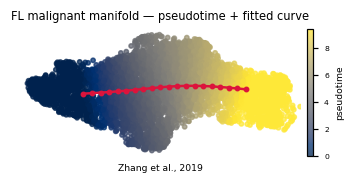

In [9]:
body.uns['epg'] = {'NodePositions': np.asarray(body.uns['epg']['NodePositions'])}
body.write(os.path.join(pth_out, 'manifold.h5ad'))
Bc = np.asarray(body.uns['graph']['B']); ii,jj = np.where(np.triu(Bc>0))
Fl = np.asarray(body.uns['F_lin'])
xl = body.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sca = ax.scatter(xl[:,0], xl[:,1], c=t, cmap='cividis', s=8, alpha=.75)
for a,b in zip(ii,jj):
    ax.plot([Fl[a,0],Fl[b,0]], [Fl[a,1],Fl[b,1]], '-', color='crimson', lw=1.6, zorder=5)
ax.scatter(Fl[:,0], Fl[:,1], c='crimson', s=8, zorder=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py); ax.axis('off')
ax.set_title('FL malignant manifold — pseudotime + fitted curve', size=7.5)
cb = plt.colorbar(sca, ax=ax, fraction=0.035, pad=0.02); cb.set_label('pseudotime', size=6); cb.ax.tick_params(labelsize=5)
ax.text(.5,-.12,'Zhang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight'); plt.show()
print('saved manifold.h5ad + manifold.pdf | Body cells:', body.shape[0])